# Concrete compressive strength: Abrams' law vs machine learning

**Question.** How much of concrete strength can a simple physical law explain, and what does machine learning add on top of it?

**Data.** UCI *Concrete Compressive Strength* dataset: 1,030 tests, 8 inputs (kg/m³ of cement, blast-furnace slag, fly ash, water, superplasticizer, coarse and fine aggregate, plus age in days), and compressive strength in MPa as the output.
Original paper: I-C. Yeh, *Cement and Concrete Research* 28(12) (1998) 1797–1808.

**Physics used**
1. **Hydration.** Cement reacts with water to form C-S-H gel, the "glue". Water that does not react leaves capillary pores, which are weak spots.
2. **Abrams' law.** $f_c = A / B^{\,w/c}$. Strength falls exponentially with the water/cement ratio. Taking logs gives $\ln f_c = \ln A - (w/c)\ln B$, which is a straight line.
3. **Age.** Strength grows fast and then slows, roughly linearly in $\ln(\text{age})$.
4. **Pozzolanic reaction.** Fly ash and slag (supplementary cementitious materials, SCMs) react slowly with the Ca(OH)₂ that cement releases. This makes extra C-S-H *later*, so SCM concretes are weaker early and catch up later.

**Plan**
1. Audit the data (duplicates, and how many distinct mixes there really are).
2. Test Abrams' law using w/c versus w/b (water/binder, where binder = cement + slag + fly ash).
3. Measure the pozzolanic effect directly.
4. Build a 4-coefficient physics model.
5. Compare it with linear regression and random forest, under **random** and **grouped-by-mix** cross-validation.

In [1]:
# Run once if needed:  pip install numpy pandas scipy scikit-learn matplotlib
import os, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error

SEED = 0
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Load the data

The official copy is an Excel file inside a zip on the UCI site. For convenience this downloads a CSV mirror of the same 1,030 rows and checks it against known values from the UCI file. If you prefer, download `Concrete_Data.xls` from UCI yourself, save it as `data/concrete.csv` with the same column names, and this cell will use it instead.

In [2]:
PATH = "data/concrete.csv"
URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/concrete.csv"
if not os.path.exists(PATH):
    urllib.request.urlretrieve(URL, PATH)

raw = pd.read_csv(PATH)
raw.columns = ["cement", "slag", "ash", "water", "superplastic", "coarseagg", "fineagg", "age", "strength"]

# Sanity checks against the UCI original
assert len(raw) == 1030, len(raw)
assert np.isclose(raw.loc[0, "strength"], 79.99) and raw.loc[0, "cement"] == 540
print(raw.shape); raw.describe().round(1).T

(1030, 9)


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.2,104.5,102.0,192.4,272.9,350.0,540.0
slag,1030.0,73.9,86.3,0.0,0.0,22.0,143.0,359.4
ash,1030.0,54.2,64.0,0.0,0.0,0.0,118.3,200.1
water,1030.0,181.6,21.4,121.8,164.9,185.0,192.0,247.0
superplastic,1030.0,6.2,6.0,0.0,0.0,6.4,10.2,32.2
coarseagg,1030.0,972.9,77.8,801.0,932.0,968.0,1029.4,1145.0
fineagg,1030.0,773.6,80.2,594.0,731.0,779.5,824.0,992.6
age,1030.0,45.7,63.2,1.0,7.0,28.0,56.0,365.0
strength,1030.0,35.8,16.7,2.3,23.7,34.4,46.1,82.6


## 2. Data audit: duplicates and mixes

Two things matter before any modelling:
- **Exact duplicate rows** (same mix, same age, same strength) are copy errors and should be removed.
- **The same mix tested at several ages** appears as several rows. Those rows are not independent. If one row of a mix is in training and another in testing, the model has effectively seen the answer. So each distinct mix gets a `mix` ID, which is used later for grouped cross-validation.

In [3]:
COMP = ["cement", "slag", "ash", "water", "superplastic", "coarseagg", "fineagg"]
n_dup = raw.duplicated().sum()
d = raw.drop_duplicates().reset_index(drop=True)
d["mix"] = d.groupby(COMP).ngroup()

print(f"exact duplicate rows removed : {n_dup}")
print(f"rows left                    : {len(d)}")
print(f"distinct mixes               : {d['mix'].nunique()}")
print("rows per mix (count of mixes):", d.groupby('mix').size().value_counts().sort_index().to_dict())
print("tests per age (days)         :", d['age'].value_counts().sort_index().to_dict())

exact duplicate rows removed : 25
rows left                    : 1005
distinct mixes               : 427
rows per mix (count of mixes): {1: 246, 2: 42, 3: 7, 4: 37, 5: 77, 6: 12, 7: 3, 8: 2, 12: 1}
tests per age (days)         : {1: 2, 3: 129, 7: 122, 14: 62, 28: 419, 56: 86, 90: 54, 91: 17, 100: 52, 120: 3, 180: 26, 270: 13, 360: 6, 365: 14}


## 3. Physics features

- `wc`: water / cement
- `wb`: water / binder, where binder = cement + slag + fly ash
- `scm`: fraction of the binder that is slag or fly ash (0 means pure cement)
- `lnage`: ln(age in days)

In [4]:
d["binder"] = d.cement + d.slag + d.ash
d["wc"] = d.water / d.cement
d["wb"] = d.water / d.binder
d["scm"] = (d.slag + d.ash) / d.binder
d["lnage"] = np.log(d.age)
d["lnf"] = np.log(d.strength)
d[["wc", "wb", "scm", "age", "strength"]].describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
wc,1005.0,0.756,0.314,0.267,0.547,0.690,0.937,1.882
wb,1005.0,0.473,0.125,0.235,0.390,0.480,0.561,0.900
scm,1005.0,0.311,0.211,0.000,0.188,0.321,0.465,0.736
age,1005.0,45.857,63.735,1.000,7.000,28.000,56.000,365.000
strength,1005.0,35.250,16.285,2.330,23.520,33.800,44.870,82.600


## 4. Abrams' law at 28 days: w/c or w/b?

Only 28-day tests are used here, so age is held fixed. If slag and fly ash behave like cement, then **w/b** should explain strength better than **w/c**.

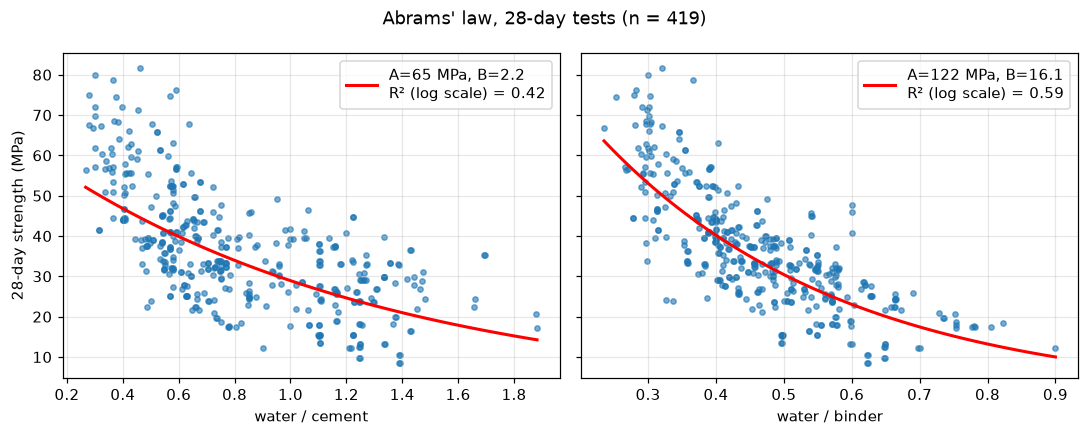

wc: A = 64.5 MPa, B = 2.23, R² = 0.419
wb: A = 122.2 MPa, B = 16.13, R² = 0.588


In [5]:
t28 = d[d.age == 28]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
abrams = {}
for ax, x in zip(axes, ["wc", "wb"]):
    lr = LinearRegression().fit(t28[[x]], t28.lnf)
    A, B = np.exp(lr.intercept_), np.exp(-lr.coef_[0])
    r2 = r2_score(t28.lnf, lr.predict(t28[[x]]))
    abrams[x] = (A, B, r2)
    xs = np.linspace(t28[x].min(), t28[x].max(), 100)
    ax.scatter(t28[x], t28.strength, s=12, alpha=0.6)
    ax.plot(xs, A / B**xs, "r-", lw=2, label=f"A={A:.0f} MPa, B={B:.1f}\nR² (log scale) = {r2:.2f}")
    ax.set_xlabel(x.replace("wc", "water / cement").replace("wb", "water / binder")); ax.legend()
axes[0].set_ylabel("28-day strength (MPa)")
fig.suptitle(f"Abrams' law, 28-day tests (n = {len(t28)})"); fig.tight_layout()
fig.savefig("figures/abrams_law.png", bbox_inches="tight"); plt.show()
for k, (A, B, r2) in abrams.items(): print(f"{k}: A = {A:.1f} MPa, B = {B:.2f}, R² = {r2:.3f}")

**What to look for.** w/b gives a clearly higher R² than w/c. Slag and fly ash act as **binder**: they make C-S-H too, so counting only cement understates the "glue". Abrams' law still leaves a lot unexplained even at fixed age, because aggregates, superplasticizer and the amount of SCM also matter.

## 5. The pozzolanic effect, measured directly

For mixes tested at two ages, compute the strength ratio:
- **7 d / 28 d.** How much of the 28-day strength is already there at 7 days. This is expected to be *lower* for high-SCM mixes.
- **90 d / 28 d.** How much strength is gained after 28 days. This is expected to be *higher* for high-SCM mixes.

In [6]:
mix_mean = d.groupby(["mix", "age"]).strength.mean().unstack()
scm_of_mix = d.groupby("mix").scm.first()

def gain_table(num, den):
    # strength at age `num` divided by strength at age `den`, same mix
    s = mix_mean[[num, den]].dropna()
    ratio = s[num] / s[den]
    grp = np.where(scm_of_mix.loc[s.index] == 0, "no SCM", np.where(scm_of_mix.loc[s.index] >= 0.3, "SCM >= 30%", "SCM < 30%"))
    return pd.DataFrame({"ratio": ratio.values, "group": grp})

rows = []
for (num, den), label in [((7, 28), "7d / 28d"), ((90, 28), "90d / 28d")]:
    g = gain_table(num, den)
    out = g.groupby("group").ratio.agg(["mean", "count"]).round(2)
    out["ratio"] = label; rows.append(out.reset_index())
    no, hi = g[g.group == "no SCM"].ratio, g[g.group == "SCM >= 30%"].ratio
    if len(no) > 2 and len(hi) > 2:
        p = stats.mannwhitneyu(no, hi).pvalue
        print(f"{label}: no SCM {no.mean():.2f} (n={len(no)})  vs  SCM>=30% {hi.mean():.2f} (n={len(hi)})   Mann-Whitney p = {p:.3g}")
pd.concat(rows)[["ratio", "group", "mean", "count"]]

7d / 28d: no SCM 0.65 (n=45)  vs  SCM>=30% 0.56 (n=50)   Mann-Whitney p = 1.32e-05
90d / 28d: no SCM 1.19 (n=23)  vs  SCM>=30% 1.30 (n=25)   Mann-Whitney p = 0.000386


,ratio,group,mean,count
0,7d / 28d,SCM < 30%,0.79,19
1,7d / 28d,SCM >= 30%,0.56,50
2,7d / 28d,no SCM,0.65,45
0,90d / 28d,SCM < 30%,1.08,3
1,90d / 28d,SCM >= 30%,1.30,25
2,90d / 28d,no SCM,1.19,23


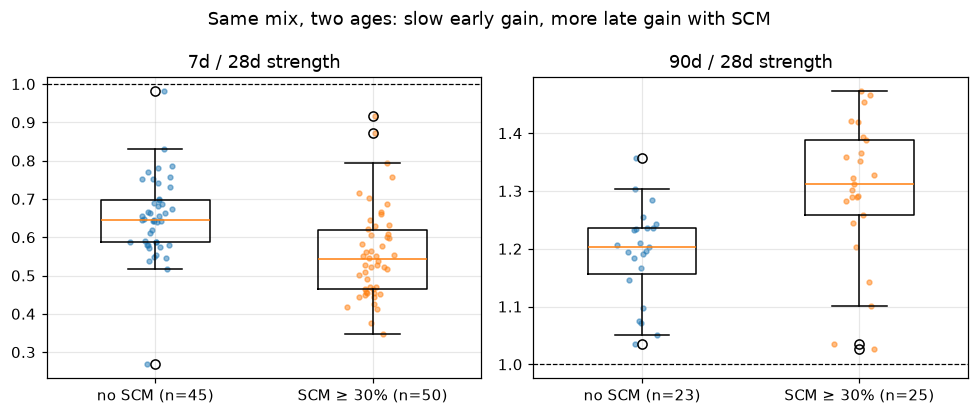

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, ((num, den), label) in zip(axes, [((7, 28), "7d / 28d strength"), ((90, 28), "90d / 28d strength")]):
    g = gain_table(num, den)
    data = [g[g.group == "no SCM"].ratio, g[g.group == "SCM >= 30%"].ratio]
    ax.boxplot(data, widths=0.5)
    for i, v in enumerate(data, start=1):
        ax.scatter(np.random.default_rng(SEED).normal(i, 0.05, len(v)), v, s=10, alpha=0.5)
    ax.set_xticks([1, 2], [f"no SCM (n={len(data[0])})", f"SCM ≥ 30% (n={len(data[1])})"])
    ax.axhline(1, color="k", lw=0.8, ls="--"); ax.set_title(label)
fig.suptitle("Same mix, two ages: slow early gain, more late gain with SCM"); fig.tight_layout()
fig.savefig("figures/pozzolanic_ratios.png", bbox_inches="tight"); plt.show()

*Why ratios and not a plain strength-vs-age curve?* Different ages in this dataset were tested on different mixes, often from different labs, so a plain curve mixes up age with mix design. A ratio compares each mix **with itself**, which cancels w/b, aggregates and lab differences.

## 6. A 4-coefficient physics model

$$\ln f_c = a + b\,(w/b) + c\,\ln(\text{age}) + d\,\text{SCM} + e\,\text{SCM}\cdot\ln(\text{age})$$

- $b$ is Abrams' law (expected negative).
- $c$ is the age effect (expected positive).
- $d$ and $e$ are the pozzolanic effect: SCM costs strength early ($d<0$) but the penalty shrinks with age ($e>0$).

Setting $d + e\ln t = 0$ gives the **age at which SCM stops costing strength**: $t^* = e^{-d/e}$.

In [8]:
PHYS = ["wb", "lnage", "scm", "scm_lnage"]
d["scm_lnage"] = d.scm * d.lnage
phys = LinearRegression().fit(d[PHYS], d.lnf)
coef = dict(zip(PHYS, phys.coef_))
print(f"a (intercept)   = {phys.intercept_:+.3f}")
for k, v in coef.items(): print(f"{k:15s} = {v:+.3f}")
t_star = np.exp(-coef["scm"] / coef["scm_lnage"])
print(f"\nSCM break-even age t* = {t_star:.0f} days")
for age in [7, 28, 90, 365]:
    effect = np.exp(0.3 * (coef["scm"] + coef["scm_lnage"] * np.log(age))) - 1
    print(f"30% SCM at {age:3d} d changes strength by {100*effect:+.0f}% (same w/b)")

a (intercept)   = +4.257
wb              = -2.905
lnage           = +0.226
scm             = -1.416
scm_lnage       = +0.282

SCM break-even age t* = 152 days
30% SCM at   7 d changes strength by -23% (same w/b)
30% SCM at  28 d changes strength by -13% (same w/b)
30% SCM at  90 d changes strength by -4% (same w/b)
30% SCM at 365 d changes strength by +8% (same w/b)


## 7. Models and the leakage check

| Model | Inputs |
|---|---|
| Linear regression (raw) | the 8 raw columns |
| Physics model | `wb`, `lnage`, `scm`, `scm·lnage` (fitted on ln strength) |
| Random forest (raw) | the 8 raw columns |
| Random forest (+ physics) | raw columns + `wb` + `scm` |

Every model is scored two ways:
- **Random 5-fold CV.** Rows are shuffled, so the same mix can sit in both training and test.
- **Grouped 5-fold CV.** Each mix is entirely in training or entirely in test. This is the honest question: *how well do we predict a mix we have never seen?*

In [9]:
RAW = COMP + ["age"]
y, groups = d.strength.values, d.mix.values
CVS = {"random": KFold(5, shuffle=True, random_state=SEED), "grouped": GroupKFold(5)}
rf = lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
MODELS = {
    "Linear regression (raw)": (LinearRegression(), RAW, False),
    "Physics model (4 coef)":  (LinearRegression(), PHYS, True),
    "Random forest (raw)":     (rf(), RAW, False),
    "Random forest (+physics)": (rf(), RAW + ["wb", "scm"], False),
}
res, preds = [], {}
for name, (model, cols, log_target) in MODELS.items():
    for cv_name, cv in CVS.items():
        target = np.log(y) if log_target else y
        p = cross_val_predict(model, d[cols], target, cv=cv, groups=groups if cv_name == "grouped" else None)
        p = np.exp(p) if log_target else p
        preds[(name, cv_name)] = p
        res.append({"model": name, "CV": cv_name, "R2": r2_score(y, p), "MAE (MPa)": mean_absolute_error(y, p)})
res = pd.DataFrame(res)
table = res.pivot(index="model", columns="CV", values=["R2", "MAE (MPa)"]).round(3)
table["R2 drop (random - grouped)"] = (table[("R2", "random")] - table[("R2", "grouped")]).round(3)
table.loc[list(MODELS)]

R2        MAE (MPa)         \
CV                       grouped random   grouped random   
model                                                      
Linear regression (raw)    0.584  0.592     8.315  8.225   
Physics model (4 coef)     0.755  0.759     5.749  5.714   
Random forest (raw)        0.851  0.898     4.458  3.727   
Random forest (+physics)   0.874  0.898     4.031  3.658   

                         R2 drop (random - grouped)  
CV                                                   
model                                                
Linear regression (raw)                       0.008  
Physics model (4 coef)                        0.004  
Random forest (raw)                           0.047  
Random forest (+physics)                      0.024

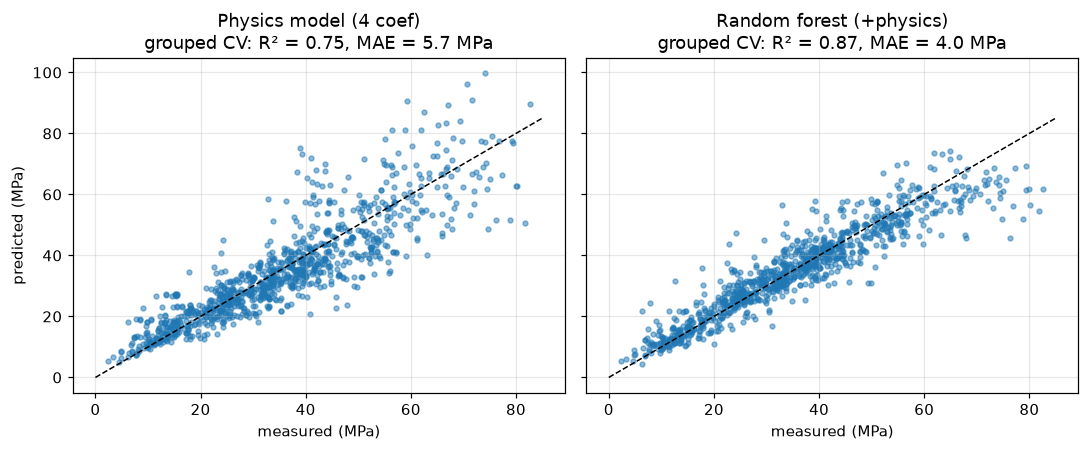

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, name in zip(axes, ["Physics model (4 coef)", "Random forest (+physics)"]):
    p = preds[(name, "grouped")]
    ax.scatter(y, p, s=10, alpha=0.5)
    ax.plot([0, 85], [0, 85], "k--", lw=1)
    ax.set_title(f"{name}\ngrouped CV: R² = {r2_score(y, p):.2f}, MAE = {mean_absolute_error(y, p):.1f} MPa")
    ax.set_xlabel("measured (MPa)")
axes[0].set_ylabel("predicted (MPa)"); fig.tight_layout()
fig.savefig("figures/parity_grouped.png", bbox_inches="tight"); plt.show()

**What to look for**
- The physics model uses 4 coefficients and beats raw linear regression on 8 inputs. Putting the physics into the features (log of age, ratios) matters more than adding variables.
- The random forest is the most accurate. It drops noticeably under grouped CV, though, which is the leakage that random splits hide. Many published results on this dataset use random splits.
- Adding the physics features (`wb`, `scm`) helps the forest most under grouped CV, which is exactly when it has to generalise to new mixes.

## 8. What does the random forest rely on?

Permutation importance is measured on held-out mixes: shuffle one input and see how much the error grows. If the forest has learned physics, age and water/binder should be at the top.

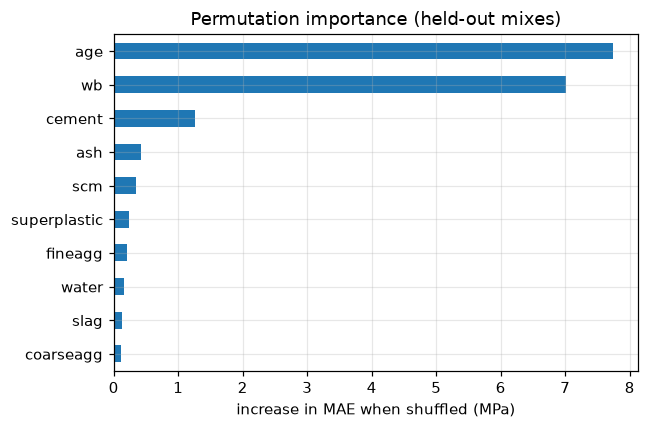

age             7.74
wb              7.01
cement          1.27
ash             0.42
scm             0.34
superplastic    0.23
fineagg         0.21
water           0.16
slag            0.13
coarseagg       0.12
dtype: float64

In [11]:
cols = RAW + ["wb", "scm"]
imps = []
for k, (tr, te) in enumerate(GroupKFold(5).split(d, y, groups)):
    m = rf().fit(d.iloc[tr][cols], y[tr])
    pi = permutation_importance(m, d.iloc[te][cols], y[te], n_repeats=10, random_state=SEED, scoring="neg_mean_absolute_error")
    imps.append(pi.importances_mean)
imp = pd.Series(np.mean(imps, axis=0), index=cols).sort_values()
ax = imp.plot.barh(figsize=(6, 4), color="C0")
ax.set_xlabel("increase in MAE when shuffled (MPa)"); ax.set_title("Permutation importance (held-out mixes)")
plt.tight_layout(); plt.savefig("figures/importance.png", bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).round(2)

## 9. Summary (numbers from the reference run; check yours match)

1. **Data audit.** 25 exact duplicates were removed. The 1,005 remaining rows come from only 427 distinct mixes, so rows are not independent.
2. **Abrams' law** at 28 days: R² = 0.59 with water/**binder** vs 0.42 with water/cement. Slag and fly ash act as binder.
3. **Pozzolanic effect.** For mixes with ≥30% SCM, 7-day strength is 56% of 28-day (vs 65% without SCM). From 28 to 90 days they gain 30% more strength (vs 19%). Both differences have Mann-Whitney p < 0.001. The physics model says 30% SCM costs about 23% strength at 7 days, 13% at 28 days, and breaks even at about 150 days.
4. **Physics model vs ML** (grouped CV):
   - 4-coefficient physics model: R² 0.76, MAE 5.7 MPa.
   - Raw linear regression: R² 0.58.
   - Random forest with physics features: R² 0.87, MAE 4.0 MPa.
   - Random splits make the forest look better than it is (raw forest drops from R² 0.90 to 0.85).
5. **The forest relies mostly on age and water/binder**, the same two variables Abrams' law and hydration point to.

**Limitations.** No cement chemistry (C₃S content, fineness), curing temperature, or aggregate type. The data come from many labs, so some scatter is between labs rather than physics.

### Likely interview questions
- *Why does water weaken concrete?* Extra water leaves capillary pores, and pores concentrate stress.
- *Why use ln(age)?* Hydration slows as grains get coated with gel, so strength grows fast and then levels off.
- *Why grouped CV?* The same mix appears at several ages. A random split lets the model "recognise" the mix instead of predicting it.
- *Why did the forest beat the physics model?* It captures effects the 4-term model leaves out, such as superplasticizer and aggregates, and interactions between them. The physics model trades some accuracy for coefficients you can explain.